In [1]:
# Data analysis
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# File and system utilities
from pathlib import Path

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.2f}".format)

# Visualization settings
sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")

ModuleNotFoundError: No module named 'seaborn'

In [2]:
%pip install seaborn

  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
Note: you may need to restart the kernel to use updated packages.


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.2f}".format)

sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


In [4]:
from pathlib import Path

# Layihənin əsas qovluğunu müəyyən edirik
DATA_DIR = Path("data")

# CSV fayllarının yollarını müəyyən edirik
JAN_FILE = DATA_DIR / "2020-Jan.csv"
FEB_FILE = DATA_DIR / "2020-Feb.csv"

# Faylların mövcudluğunu və ölçüsünü yoxlayırıq
for file_path in [JAN_FILE, FEB_FILE]:
    print(f"File: {file_path}")
    print(f"Exists: {file_path.exists()}")

    if file_path.exists():
        print(f"Size: {file_path.stat().st_size / (1024 ** 2):.2f} MB")

    print("-" * 40)

File: data\2020-Jan.csv
Exists: True
Size: 478.55 MB
----------------------------------------
File: data\2020-Feb.csv
Exists: True
Size: 466.16 MB
----------------------------------------


In [5]:
# Yanvar və fevral məlumatlarını oxuyuruq
jan_df = pd.read_csv(JAN_FILE)
feb_df = pd.read_csv(FEB_FILE)

# Hər faylın ölçüsünü yoxlayırıq
print("January shape:", jan_df.shape)
print("February shape:", feb_df.shape)

January shape: (4264752, 9)
February shape: (4156682, 9)


In [6]:
# Yanvar və fevral məlumatlarını bir DataFrame-də birləşdiririk
df = pd.concat([jan_df, feb_df], ignore_index=True)

# Birləşdirilmiş məlumatları yoxlayırıq
print("Combined dataset shape:", df.shape)

# İlk 5 sətri göstəririk
display(df.head())

Combined dataset shape: (8421434, 9)


,event_time,event_type,product_id,category_id,category_code,brand,price,user_id,user_session
0,2020-01-01 00:00:00 UTC,view,5809910,1602943681873052386,NaN,grattol,5.24,595414620,4adb70bb-edbd-4981-b60f-a05bfd32683a
1,2020-01-01 00:00:09 UTC,view,5812943,1487580012121948301,NaN,kinetics,3.97,595414640,c8c5205d-be43-4f1d-aa56-4828b8151c8a
2,2020-01-01 00:00:19 UTC,view,5798924,1783999068867920626,NaN,zinger,3.97,595412617,46a5010f-bd69-4fbe-a00d-bb17aa7b46f3
3,2020-01-01 00:00:24 UTC,view,5793052,1487580005754995573,NaN,NaN,4.92,420652863,546f6af3-a517-4752-a98b-80c4c5860711
4,2020-01-01 00:00:25 UTC,view,5899926,2115334439910245200,NaN,NaN,3.92,484071203,cff70ddf-529e-4b0c-a4fc-f43a749c0acb


In [7]:
# Hər event_type üzrə hadisələrin sayını hesablayırıq
event_counts = df["event_type"].value_counts()

# Ümumi hadisə sayına görə faizləri hesablayırıq
event_percentages = df["event_type"].value_counts(normalize=True) * 100

# Nəticələri bir cədvəldə birləşdiririk
event_distribution = pd.DataFrame({
    "event_count": event_counts,
    "percentage": event_percentages
})

# Faizləri iki rəqəm dəqiqliyi ilə göstəririk
event_distribution["percentage"] = (
    event_distribution["percentage"].round(2)
)

display(event_distribution)

,event_count,percentage
event_type,,
view,3991194,47.39
cart,2297017,27.28
remove_from_cart,1627433,19.32
purchase,505790,6.01


In [8]:
# Sütunların məlumat tiplərini yoxlayırıq
print("DATA TYPES")
display(df.dtypes.to_frame(name="data_type"))

# Hər sütundakı boş dəyərlərin sayını hesablayırıq
print("MISSING VALUES")
missing_values = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percentage": (df.isna().mean() * 100).round(2)
})

display(missing_values)

# Datasetin ümumi məlumatını yoxlayırıq
print("DATASET INFO")
df.info()

DATA TYPES


,data_type
event_time,str
event_type,str
product_id,int64
category_id,int64
category_code,str
brand,str
price,float64
user_id,int64
user_session,str


MISSING VALUES


,missing_count,missing_percentage
event_time,0,0.00
event_type,0,0.00
product_id,0,0.00
category_id,0,0.00
category_code,8269530,98.20
brand,3601538,42.77
price,0,0.00
user_id,0,0.00
user_session,2369,0.03


DATASET INFO
<class 'pandas.DataFrame'>
RangeIndex: 8421434 entries, 0 to 8421433
Data columns (total 9 columns):
 #   Column         Dtype  
---  ------         -----  
 0   event_time     str    
 1   event_type     str    
 2   product_id     int64  
 3   category_id    int64  
 4   category_code  str    
 5   brand          str    
 6   price          float64
 7   user_id        int64  
 8   user_session   str    
dtypes: float64(1), int64(3), str(5)
memory usage: 578.3 MB


In [9]:
# Hər sütunda boş dəyərlərin sayını və faizini hesablayırıq
missing_values = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percentage": (df.isna().mean() * 100).round(2)
})

display(missing_values)

# Tarix sütunundan nümunələri göstəririk
print("Event time samples:")
display(df["event_time"].head())

# Hadisə növlərini yenidən yoxlayırıq
print("Event types:")
print(df["event_type"].value_counts())

,missing_count,missing_percentage
event_time,0,0.00
event_type,0,0.00
product_id,0,0.00
category_id,0,0.00
category_code,8269530,98.20
brand,3601538,42.77
price,0,0.00
user_id,0,0.00
user_session,2369,0.03


Event time samples:


0    2020-01-01 00:00:00 UTC
1    2020-01-01 00:00:09 UTC
2    2020-01-01 00:00:19 UTC
3    2020-01-01 00:00:24 UTC
4    2020-01-01 00:00:25 UTC
Name: event_time, dtype: str

Event types:
event_type
view                3991194
cart                2297017
remove_from_cart    1627433
purchase             505790
Name: count, dtype: int64


In [10]:

# event_time sütununu datetime formatına çeviririk
df["event_time"] = pd.to_datetime(
    df["event_time"],
    utc=True,
    errors="coerce"
)

# Çevrilmənin nəticəsini yoxlayırıq
print("Tarix sütununun tipi:", df["event_time"].dtype)
print("Çevrilə bilməyən tarixlərin sayı:", df["event_time"].isna().sum())

# Tarixlərin ilk 5 sətrini göstəririk
display(df[["event_time", "event_type"]].head())



Tarix sütununun tipi: datetime64[us, UTC]
Çevrilə bilməyən tarixlərin sayı: 0


,event_time,event_type
0,2020-01-01 00:00:00+00:00,view
1,2020-01-01 00:00:09+00:00,view
2,2020-01-01 00:00:19+00:00,view
3,2020-01-01 00:00:24+00:00,view
4,2020-01-01 00:00:25+00:00,view


In [11]:

# event_time sütununu datetime formatına çeviririk
df["event_time"] = pd.to_datetime(
    df["event_time"],
    utc=True,
    errors="coerce"
)

# Çevrilmənin nəticəsini yoxlayırıq
print("Tarix sütununun tipi:", df["event_time"].dtype)
print("Çevrilə bilməyən tarixlərin sayı:", df["event_time"].isna().sum())

# Tarixlərin ilk 5 sətrini göstəririk
display(df[["event_time", "event_type"]].head())


Tarix sütununun tipi: datetime64[us, UTC]
Çevrilə bilməyən tarixlərin sayı: 0


,event_time,event_type
0,2020-01-01 00:00:00+00:00,view
1,2020-01-01 00:00:09+00:00,view
2,2020-01-01 00:00:19+00:00,view
3,2020-01-01 00:00:24+00:00,view
4,2020-01-01 00:00:25+00:00,view


In [12]:

# Hər hadisənin ayını ayrıca sütunda saxlayırıq
df["month"] = df["event_time"].dt.strftime("%Y-%m")

# Aylar üzrə hadisələrin sayını yoxlayırıq
print("Aylar üzrə hadisə sayı:")
display(df["month"].value_counts().sort_index())

# Hər ay üzrə ilk və son tarixləri yoxlayırıq
display(
    df.groupby("month")["event_time"]
      .agg(["min", "max"])
)


Aylar üzrə hadisə sayı:


month
2020-01    4264752
2020-02    4156682
Name: count, dtype: int64

,min,max
month,,
2020-01,2020-01-01 00:00:00+00:00,2020-01-31 23:59:58+00:00
2020-02,2020-02-01 00:00:01+00:00,2020-02-29 23:59:59+00:00


In [13]:

# Hər mərhələdəki unikal istifadəçilərin sayı
funnel_events = ["view", "cart", "purchase"]

funnel_data = []

for event in funnel_events:
    users = df.loc[df["event_type"] == event, "user_id"].nunique()
    funnel_data.append({
        "stage": event,
        "unique_users": users
    })

funnel_df = pd.DataFrame(funnel_data)

# View mərhələsini başlanğıc götürərək faizləri hesablayırıq
view_users = funnel_df.loc[
    funnel_df["stage"] == "view", "unique_users"
].iloc[0]

funnel_df["percentage_of_viewers"] = (
    funnel_df["unique_users"] / view_users * 100
).round(2)

display(funnel_df)


,stage,unique_users,percentage_of_viewers
0,view,716987,100.00
1,cart,162035,22.60
2,purchase,49473,6.90


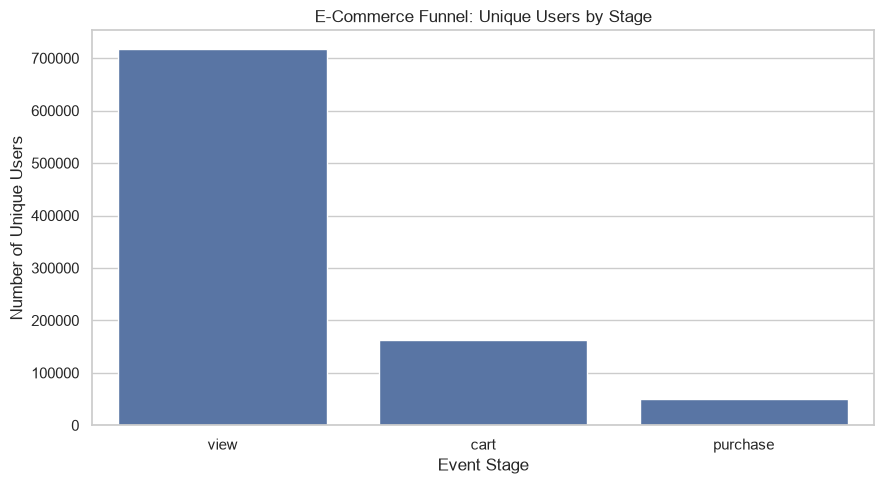

In [14]:

plt.figure(figsize=(9, 5))

sns.barplot(
    data=funnel_df,
    x="stage",
    y="unique_users"
)

plt.title("E-Commerce Funnel: Unique Users by Stage")
plt.xlabel("Event Stage")
plt.ylabel("Number of Unique Users")
plt.ticklabel_format(style="plain", axis="y")
plt.tight_layout()
plt.show()


In [15]:

# Kateqoriya məlumatı olan hadisələri seçirik
category_df = df.dropna(subset=["category_code"]).copy()

# Baxış sayına görə ən populyar 8 kateqoriyanı tapırıq
top_8_categories = (
    category_df[category_df["event_type"] == "view"]
    .groupby("category_code")["user_id"]
    .nunique()
    .sort_values(ascending=False)
    .head(8)
)

print("Baxış edən unikal istifadəçilərə görə TOP 8 kateqoriya:")
display(top_8_categories)


Baxış edən unikal istifadəçilərə görə TOP 8 kateqoriya:


category_code
appliances.environment.vacuum      15431
furniture.living_room.cabinet       5377
apparel.glove                       4965
stationery.cartrige                 4313
furniture.bathroom.bath             3602
accessories.bag                     3147
appliances.personal.massager        1335
appliances.personal.hair_cutter     1141
Name: user_id, dtype: int64

In [16]:

# TOP 8 kateqoriyanı siyahıya çeviririk
top_categories = top_8_categories.index.tolist()

# Yalnız seçilmiş 8 kateqoriyanın məlumatlarını götürürük
top_category_df = category_df[
    category_df["category_code"].isin(top_categories)
]

# Kateqoriya və hadisə növü üzrə unikal istifadəçiləri sayırıq
category_funnel = (
    top_category_df[
        top_category_df["event_type"].isin(["view", "cart", "purchase"])
    ]
    .groupby(["category_code", "event_type"])["user_id"]
    .nunique()
    .unstack(fill_value=0)
)

# Lazım olan sütunların hamısının mövcudluğunu təmin edirik
category_funnel = category_funnel.reindex(
    columns=["view", "cart", "purchase"],
    fill_value=0
)

# Konversiya faizlərini hesablayırıq
category_funnel["view_to_cart_pct"] = (
    category_funnel["cart"] / category_funnel["view"] * 100
).round(2)

category_funnel["view_to_purchase_pct"] = (
    category_funnel["purchase"] / category_funnel["view"] * 100
).round(2)

# Baxış sayına görə sıralayırıq
category_funnel = category_funnel.sort_values(
    "view", ascending=False
)

display(category_funnel)


event_type,view,cart,purchase,view_to_cart_pct,view_to_purchase_pct
category_code,,,,,
appliances.environment.vacuum,15431,3883,1366,25.16,8.85
furniture.living_room.cabinet,5377,760,119,14.13,2.21
apparel.glove,4965,4128,1932,83.14,38.91
stationery.cartrige,4313,2265,1025,52.52,23.77
furniture.bathroom.bath,3602,1164,384,32.32,10.66
accessories.bag,3147,146,45,4.64,1.43
appliances.personal.massager,1335,151,35,11.31,2.62
appliances.personal.hair_cutter,1141,113,28,9.90,2.45


In [31]:

print(category_funnel.head())
print("\nSütunlar:")
print(category_funnel.columns.tolist())
print("\nİndeks adı:")
print(category_funnel.index.name)


event_type                      view  cart  purchase  view_to_cart_pct  \
category_code                                                            
appliances.environment.vacuum  15431  3883      1366             25.16   
furniture.living_room.cabinet   5377   760       119             14.13   
apparel.glove                   4965  4128      1932             83.14   
stationery.cartrige             4313  2265      1025             52.52   
furniture.bathroom.bath         3602  1164       384             32.32   

event_type                     view_to_purchase_pct  
category_code                                        
appliances.environment.vacuum                  8.85  
furniture.living_room.cabinet                  2.21  
apparel.glove                                 38.91  
stationery.cartrige                           23.77  
furniture.bathroom.bath                       10.66  

Sütunlar:
['view', 'cart', 'purchase', 'view_to_cart_pct', 'view_to_purchase_pct']

İndeks adı:
catego

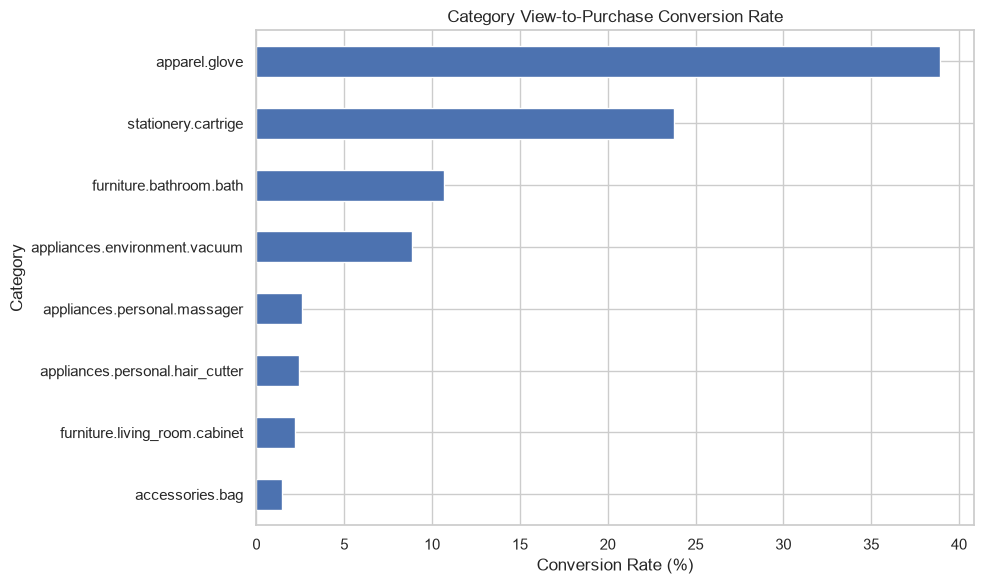

In [32]:

category_funnel["view_to_purchase_pct"].sort_values().plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title("Category View-to-Purchase Conversion Rate")
plt.xlabel("Conversion Rate (%)")
plt.ylabel("Category")
plt.tight_layout()
plt.show()


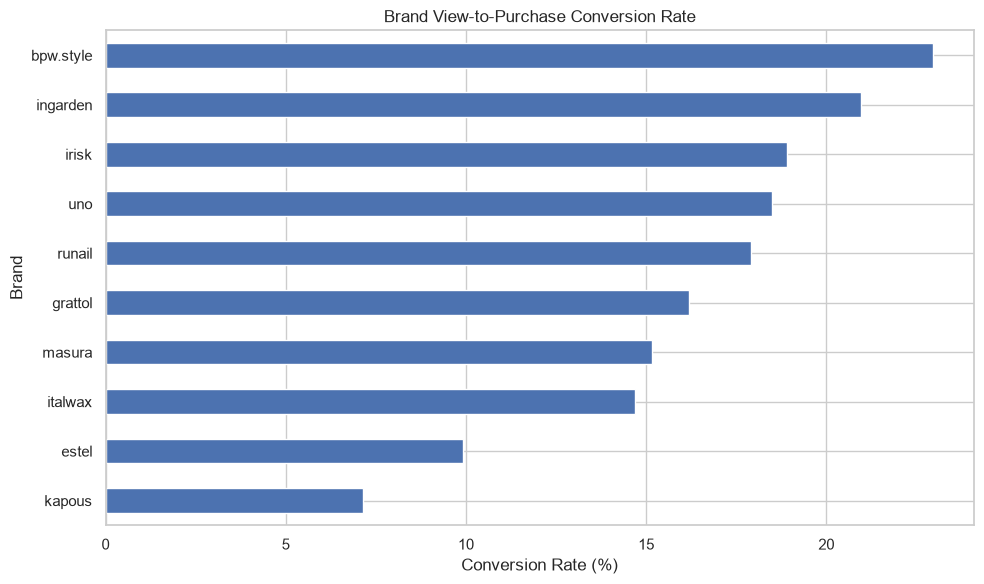

In [33]:

brand_summary["view_to_purchase_pct"].sort_values().plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title("Brand View-to-Purchase Conversion Rate")
plt.xlabel("Conversion Rate (%)")
plt.ylabel("Brand")
plt.tight_layout()
plt.show()


In [17]:

# Yanvar və fevral üzrə unikal istifadəçilərin sayı
monthly_funnel = (
    df[df["event_type"].isin(["view", "purchase"])]
    .groupby(["month", "event_type"])["user_id"]
    .nunique()
    .unstack(fill_value=0)
)

monthly_funnel = monthly_funnel.reindex(
    columns=["view", "purchase"],
    fill_value=0
)

# Baxışdan alışa konversiya faizi
monthly_funnel["view_to_purchase_pct"] = (
    monthly_funnel["purchase"] / monthly_funnel["view"] * 100
).round(2)

display(monthly_funnel)


event_type,view,purchase,view_to_purchase_pct
month,,,
2020-01,397775,28220,7.09
2020-02,379246,25759,6.79


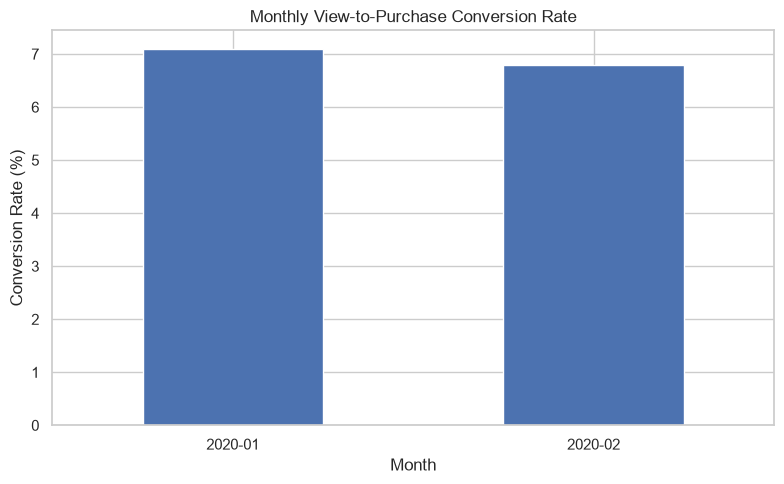

In [29]:

import matplotlib.pyplot as plt

monthly_funnel[["view_to_purchase_pct"]].plot(
    kind="bar",
    figsize=(8, 5),
    legend=False
)

plt.title("Monthly View-to-Purchase Conversion Rate")
plt.xlabel("Month")
plt.ylabel("Conversion Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [18]:

# Brendi məlum olan hadisələri seçirik
brand_df = df.dropna(subset=["brand"])

# Purchase hadisələrinin sayına görə TOP 10 brend
top_10_brands = (
    brand_df[brand_df["event_type"] == "purchase"]
    .groupby("brand")
    .size()
    .sort_values(ascending=False)
    .head(10)
    .index
)

# TOP 10 brend üçün baxış və alış göstəriciləri
brand_funnel = (
    brand_df[
        brand_df["brand"].isin(top_10_brands)
        & brand_df["event_type"].isin(["view", "purchase"])
    ]
    .groupby(["brand", "event_type"])
    .agg(
        event_count=("event_type", "size"),
        unique_users=("user_id", "nunique")
    )
)

display(brand_funnel)


event_count  unique_users
brand     event_type                           
bpw.style purchase           8437          3070
          view              43536         13376
estel     purchase           8616          3994
          view              90060         40234
grattol   purchase          21320          7905
          view             178970         48870
ingarden  purchase          10276          4972
          view              71516         23716
irisk     purchase          31210         13332
          view             179851         70510
italwax   purchase           6740          2927
          view              46180         19923
kapous    purchase           6370          3018
          view              86521         42289
masura    purchase          19929          5401
          view             143103         35640
runail    purchase          45274         15562
          view             257004         86823
uno       purchase           6871          4128
          view              50047         22313

In [19]:

# MultiIndex cədvəlini düz formaya çeviririk
brand_summary = brand_funnel["unique_users"].unstack(fill_value=0)

# Sütun adlarını aydınlaşdırırıq
brand_summary = brand_summary.rename(
    columns={
        "view": "view_users",
        "purchase": "purchase_users"
    }
)

# Hadisələrin sayını ayrıca əlavə edirik
brand_event_counts = brand_funnel["event_count"].unstack(fill_value=0)
brand_summary["purchase_events"] = brand_event_counts["purchase"]

# Baxışdan alışa konversiya faizi
brand_summary["view_to_purchase_pct"] = (
    brand_summary["purchase_users"]
    / brand_summary["view_users"]
    * 100
).round(2)

# Alış hadisələrinin sayına görə sıralayırıq
brand_summary = brand_summary.sort_values(
    "purchase_events",
    ascending=False
)

display(brand_summary)


event_type,purchase_users,view_users,purchase_events,view_to_purchase_pct
brand,,,,
runail,15562,86823,45274,17.92
irisk,13332,70510,31210,18.91
grattol,7905,48870,21320,16.18
masura,5401,35640,19929,15.15
ingarden,4972,23716,10276,20.96
estel,3994,40234,8616,9.93
bpw.style,3070,13376,8437,22.95
uno,4128,22313,6871,18.50
italwax,2927,19923,6740,14.69


In [20]:

# Yalnız alış hadisələrini götürürük
purchase_df = df[df["event_type"] == "purchase"]

# Qiymət üzrə kvartilləri hesablayırıq
Q1 = purchase_df["price"].quantile(0.25)
Q3 = purchase_df["price"].quantile(0.75)
IQR = Q3 - Q1

# Kənar dəyərlərin sərhədləri
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Kənar dəyərləri seçirik
outliers = purchase_df[
    (purchase_df["price"] < lower_bound)
    | (purchase_df["price"] > upper_bound)
]

print(f"Q1: {Q1:.2f}")
print(f"Q3: {Q3:.2f}")
print(f"IQR: {IQR:.2f}")
print(f"Aşağı sərhəd: {lower_bound:.2f}")
print(f"Yuxarı sərhəd: {upper_bound:.2f}")
print(f"Kənar qiymətlərin sayı: {len(outliers):,}")
print(f"Kənar qiymətlərin faizi: {len(outliers) / len(purchase_df) * 100:.2f}%")


Q1: 1.59
Q3: 5.56
IQR: 3.97
Aşağı sərhəd: -4.37
Yuxarı sərhəd: 11.52
Kənar qiymətlərin sayı: 34,947
Kənar qiymətlərin faizi: 6.91%


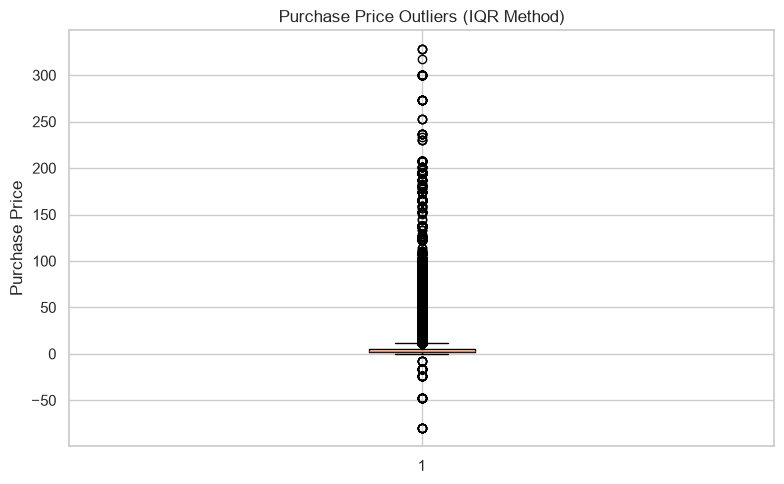

In [35]:

plt.figure(figsize=(8, 5))
plt.boxplot(purchase_df["price"].dropna())
plt.title("Purchase Price Outliers (IQR Method)")
plt.ylabel("Purchase Price")
plt.tight_layout()
plt.show()


In [21]:

# Yalnız baxış və alış hadisələrini seçirik
events = df.loc[
    df["event_type"].isin(["view", "purchase"]),
    ["user_id", "product_id", "event_type", "event_time"]
].copy()

# Eyni istifadəçi və məhsul üzrə hadisələri zamanla sıralayırıq
events = events.sort_values(
    ["user_id", "product_id", "event_time"]
)

# Hər istifadəçi-məhsul cütü üçün son əvvəlki baxış vaxtını tapırıq
group_keys = [events["user_id"], events["product_id"]]

events["last_view_time"] = (
    events["event_time"]
    .where(events["event_type"] == "view")
    .groupby(group_keys)
    .ffill()
)

# Alış hadisələrini seçirik
purchase_events = events[
    (events["event_type"] == "purchase")
    & (events["last_view_time"].notna())
].copy()

# Baxışdan alışa qədər müddəti dəqiqə ilə hesablayırıq
purchase_events["minutes_to_purchase"] = (
    purchase_events["event_time"] - purchase_events["last_view_time"]
).dt.total_seconds() / 60

# Mənfi olmayan müddətləri saxlayırıq
purchase_events = purchase_events[
    purchase_events["minutes_to_purchase"] >= 0
]

print("Əvvəlki baxışı tapılmış alış hadisələrinin sayı:",
      f"{len(purchase_events):,}")
print("Orta müddət (dəqiqə):",
      round(purchase_events["minutes_to_purchase"].mean(), 2))
print("Median müddət (dəqiqə):",
      round(purchase_events["minutes_to_purchase"].median(), 2))


Əvvəlki baxışı tapılmış alış hadisələrinin sayı: 182,132
Orta müddət (dəqiqə): 2069.81
Median müddət (dəqiqə): 34.22


In [ ]:
print("January rows:", len(jan_df))
print("February rows:", len(feb_df))
print("Combined rows:", len(df))

print("\nColumn names:")
print(df.columns.tolist())

print("\nMonth counts:")
print(df["month"].value_counts().sort_index())

print("\nEvent types:")
print(df["event_type"].value_counts())

January rows: 4264752
February rows: 4156682
Combined rows: 8421434

Column names:
['event_time', 'event_type', 'product_id', 'category_id', 'category_code', 'brand', 'price', 'user_id', 'user_session', 'month']

Month counts:
month
2020-01    4264752
2020-02    4156682
Name: count, dtype: int64

Event types:
event_type
view                3991194
cart                2297017
remove_from_cart    1627433
purchase             505790
Name: count, dtype: int64


In [22]:

# View və purchase hadisələrini məhsul üzrə qruplaşdırırıq
product_events = df[
    df["event_type"].isin(["view", "purchase"])
]

product_summary = (
    product_events
    .groupby(["product_id", "event_type"])["user_id"]
    .nunique()
    .unstack(fill_value=0)
)

# Hər iki sütunun mövcud olmasını təmin edirik
product_summary = product_summary.reindex(
    columns=["view", "purchase"],
    fill_value=0
)

product_summary = product_summary.rename(
    columns={
        "view": "view_users",
        "purchase": "purchase_users"
    }
)

# Yalnız ən azı 100 unikal baxış edən istifadəçisi olan məhsullar
product_summary = product_summary[
    product_summary["view_users"] >= 100
].copy()

# Baxışdan alışa keçid göstəricisi
product_summary["view_to_purchase_pct"] = (
    product_summary["purchase_users"]
    / product_summary["view_users"]
    * 100
).round(2)

# Ən çox baxış alan, amma konversiyası ən aşağı olan 10 məhsul
low_conversion_products = product_summary.sort_values(
    ["view_users", "view_to_purchase_pct"],
    ascending=[False, True]
).head(10)

display(low_conversion_products)


event_type,view_users,purchase_users,view_to_purchase_pct
product_id,,,
5809910,25083,3254,12.97
5808664,10426,22,0.21
5917178,8374,333,3.98
5809912,8280,1415,17.09
5751383,6735,1062,15.77
5751422,5928,1284,21.66
5849033,5736,1056,18.41
5790563,5530,401,7.25
5877456,5411,21,0.39


In [23]:

# Ən azı 1,000 unikal baxış edən istifadəçisi olan məhsullar
high_view_products = product_summary[
    product_summary["view_users"] >= 1000
].copy()

# Ən aşağı konversiyalı məhsulları önə çıxarırıq
low_conversion_products = (
    high_view_products
    .sort_values(
        ["view_to_purchase_pct", "view_users"],
        ascending=[True, False]
    )
    .head(10)
)

display(low_conversion_products)


event_type,view_users,purchase_users,view_to_purchase_pct
product_id,,,
5915337,4818,5,0.10
5805511,1004,2,0.20
5808664,10426,22,0.21
5879280,3542,8,0.23
5714240,1115,3,0.27
5770029,2564,9,0.35
5877456,5411,21,0.39
5896420,4931,26,0.53
5769925,2637,14,0.53


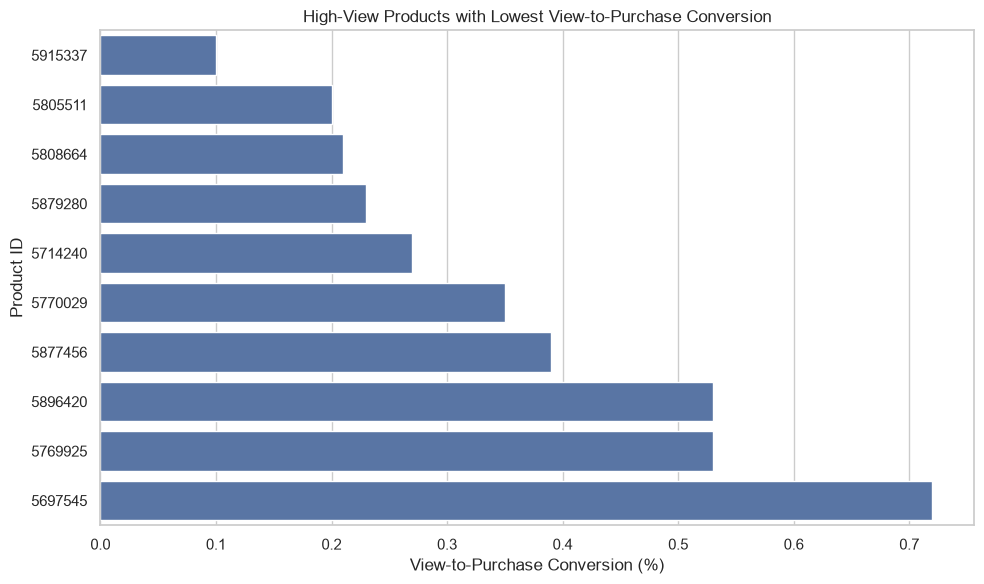

In [24]:

product_plot = low_conversion_products.reset_index().copy()

# Məhsul ID-lərini mətnə çeviririk ki, qrafikdə düzgün görünsün
product_plot["product_id"] = product_plot["product_id"].astype(str)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=product_plot.sort_values("view_to_purchase_pct", ascending=True),
    x="view_to_purchase_pct",
    y="product_id"
)

plt.title("High-View Products with Lowest View-to-Purchase Conversion")
plt.xlabel("View-to-Purchase Conversion (%)")
plt.ylabel("Product ID")
plt.tight_layout()
plt.show()


In [25]:

# Hər ay və hadisə növü üzrə hadisələrin sayını hesablayırıq
monthly_events = (
    df.groupby(["month", "event_type"])
      .size()
      .unstack(fill_value=0)
)

display(monthly_events)


event_type,cart,purchase,remove_from_cart,view
month,,,,
2020-01,1148323,263797,815024,2037608
2020-02,1148694,241993,812409,1953586


In [26]:

jan_purchases = monthly_events.loc["2020-01", "purchase"]
feb_purchases = monthly_events.loc["2020-02", "purchase"]

purchase_change_pct = (
    (feb_purchases - jan_purchases) / jan_purchases * 100
)

print(f"January purchase events: {jan_purchases:,}")
print(f"February purchase events: {feb_purchases:,}")
print(f"Change in purchase events: {purchase_change_pct:.2f}%")


January purchase events: 263,797
February purchase events: 241,993
Change in purchase events: -8.27%


In [27]:

# Layihənin əsas məlumatlarını yoxlayırıq
print("January rows:", len(jan_df))
print("February rows:", len(feb_df))
print("Combined rows:", len(df))

print("\nColumn names:")
print(df.columns.tolist())

print("\nMonth counts:")
print(df["month"].value_counts().sort_index())

print("\nEvent types:")
print(df["event_type"].value_counts())


January rows: 4264752
February rows: 4156682
Combined rows: 8421434

Column names:
['event_time', 'event_type', 'product_id', 'category_id', 'category_code', 'brand', 'price', 'user_id', 'user_session', 'month']

Month counts:
month
2020-01    4264752
2020-02    4156682
Name: count, dtype: int64

Event types:
event_type
view                3991194
cart                2297017
remove_from_cart    1627433
purchase             505790
Name: count, dtype: int64


In [28]:
print("January rows:", len(jan_df))
print("February rows:", len(feb_df))
print("Combined rows:", len(df))

print("\nColumn names:")
print(df.columns.tolist())

print("\nMonth counts:")
print(df["month"].value_counts().sort_index())

print("\nEvent types:")
print(df["event_type"].value_counts())

January rows: 4264752
February rows: 4156682
Combined rows: 8421434

Column names:
['event_time', 'event_type', 'product_id', 'category_id', 'category_code', 'brand', 'price', 'user_id', 'user_session', 'month']

Month counts:
month
2020-01    4264752
2020-02    4156682
Name: count, dtype: int64

Event types:
event_type
view                3991194
cart                2297017
remove_from_cart    1627433
purchase             505790
Name: count, dtype: int64


In [34]:

print("1. E-commerce Funnel: Unique Users by Stage")
display(funnel_df)

print("\n2. Monthly View-to-Purchase Conversion Rate")
display(monthly_funnel)

print("\n3. Category View-to-Purchase Conversion Rate")
display(category_funnel)

print("\n4. Brand View-to-Purchase Conversion Rate")
display(brand_summary)

print("\n5. High-View Products with Lowest View-to-Purchase Conversion")
display(low_conversion_products)


1. E-commerce Funnel: Unique Users by Stage


,stage,unique_users,percentage_of_viewers
0,view,716987,100.00
1,cart,162035,22.60
2,purchase,49473,6.90



2. Monthly View-to-Purchase Conversion Rate


event_type,view,purchase,view_to_purchase_pct
month,,,
2020-01,397775,28220,7.09
2020-02,379246,25759,6.79



3. Category View-to-Purchase Conversion Rate


event_type,view,cart,purchase,view_to_cart_pct,view_to_purchase_pct
category_code,,,,,
appliances.environment.vacuum,15431,3883,1366,25.16,8.85
furniture.living_room.cabinet,5377,760,119,14.13,2.21
apparel.glove,4965,4128,1932,83.14,38.91
stationery.cartrige,4313,2265,1025,52.52,23.77
furniture.bathroom.bath,3602,1164,384,32.32,10.66
accessories.bag,3147,146,45,4.64,1.43
appliances.personal.massager,1335,151,35,11.31,2.62
appliances.personal.hair_cutter,1141,113,28,9.90,2.45



4. Brand View-to-Purchase Conversion Rate


event_type,purchase_users,view_users,purchase_events,view_to_purchase_pct
brand,,,,
runail,15562,86823,45274,17.92
irisk,13332,70510,31210,18.91
grattol,7905,48870,21320,16.18
masura,5401,35640,19929,15.15
ingarden,4972,23716,10276,20.96
estel,3994,40234,8616,9.93
bpw.style,3070,13376,8437,22.95
uno,4128,22313,6871,18.50
italwax,2927,19923,6740,14.69



5. High-View Products with Lowest View-to-Purchase Conversion


event_type,view_users,purchase_users,view_to_purchase_pct
product_id,,,
5915337,4818,5,0.10
5805511,1004,2,0.20
5808664,10426,22,0.21
5879280,3542,8,0.23
5714240,1115,3,0.27
5770029,2564,9,0.35
5877456,5411,21,0.39
5896420,4931,26,0.53
5769925,2637,14,0.53
